# Compute UMAPs outside of model training pipeline

Extract the key UMAP functions from the OOP framework so that I can compute for any data.

In [3]:
from os.path import join
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import torch
import polars as pl
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

from cytoself.analysis.analysis_opencell import AnalysisOpenCell
from cytoself.datamanager.opencell import DataManagerOpenCell
from cytoself.trainer.cytoselflite_trainer import CytoselfFullTrainer
from cytoself.trainer.utils.plot_history import plot_history_cytoself
from cytoself.analysis.utils.cluster_score import calculate_cluster_centrosize

/home/shenrunx/software/anaconda3/envs/cytoself/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
datapath = '../model_inputs/2024_01_Batch_7-8'
outputpath = "../trained_models/varchamp_v2"
model_nm = "model_30.pt"
data_ch = ['pro', 'nuc']
device="cuda:0"
model_path = f"{outputpath}/{model_nm}"

In [4]:
# datamanager = DataManagerOpenCell(datapath, data_ch, fov_col=None)
# datamanager.const_dataloader(batch_size=64, label_name_position=1)

In [6]:
# model_args = {
#     "input_shape": (2, 100, 100),
#     "emb_shapes": ((25, 25), (4, 4)),
#     "output_shape": (2, 100, 100),
#     "fc_output_idx": [2],
#     "vq_args": {"num_embeddings": 512, "embedding_dim": 64},
#     "num_class": len(datamanager.unique_labels),
#     "fc_input_type": "vqvec",
# }

# train_args = {
#     "lr": 0.0004,
#     "max_epoch": 100,
#     "reducelr_patience": 4,
#     "reducelr_increment": 0.1,
#     "earlystop_patience": 12,
# }

In [4]:
# trainer = CytoselfFullTrainer(train_args, homepath=outputpath, model_args=model_args)

# modified ../cytoself/trainer/basetrainer.py due to the following error:
# File ~/igvf/varchamp/2025_laval_submitted/2_individual_assay_results/imaging/2_analysis/3_cytoself/cytoself/trainer/basetrainer.py:550, in BaseTrainer.load_model(self, path, by_weights)
#     537 def load_model(self, path: str, by_weights: bool = True) -> None:
#     538     """
#     539     Load a pytorch model
#     540 
#    (...)
#     548 
#     549     """
# --> 550     _model = torch.load(path)
# UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
# 	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
# `weights_only = False` added.

# trainer.load_model(model_path)

In [ ]:
## infer embeddings
test_embeddings = trainer.infer_embeddings(datamanager.test_loader)

if isinstance(test_embeddings, tuple) and len(test_embeddings) > 1:
    test_embeddings = test_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
# np.save(join(savepath_embeddings, 'embeddings_testdata.npy'), test_embeddings)

Infer: 100%|██████████| 1037/1037 [00:18<00:00, 56.26it/s]


In [ ]:
# infer embeddings for training data 
train_embeddings = trainer.infer_embeddings(datamanager.train_loader)
if isinstance(train_embeddings, tuple) and len(train_embeddings) > 1:
    train_embeddings = train_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
# np.save(join(savepath_embeddings, 'embeddings_traindata.npy'), train_embeddings)

Infer: 100%|██████████| 10367/10367 [05:06<00:00, 33.82it/s]


In [ ]:
# save labels by data
train_labels = datamanager.train_loader.dataset.label
# np.save(join(savepath_embeddings, 'labels_traindata.npy'), train_labels)

test_labels = datamanager.test_loader.dataset.label
# np.save(join(savepath_embeddings, 'labels_testdata.npy'), test_labels)

In [13]:
import umap.umap_ as umap
import matplotlib.colors as mcolors
import matplotlib

n_neighbors=15
min_dist=0.1
metric='euclidean'
verbose=True

reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist, metric=metric, verbose=verbose)
umap_data = reducer.fit_transform(test_embeddings.reshape(test_embeddings.shape[0], -1))

UMAP( verbose=True)
Wed Apr  9 20:47:53 2025 Construct fuzzy simplicial set
Wed Apr  9 20:47:53 2025 Finding Nearest Neighbors
Wed Apr  9 20:47:53 2025 Building RP forest with 18 trees
Wed Apr  9 20:47:58 2025 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	 4  /  16
	Stopping threshold met -- exiting after 4 iterations
Wed Apr  9 20:48:16 2025 Finished Nearest Neighbor Search
Wed Apr  9 20:48:19 2025 Construct embedding


Epochs completed: 100%| ██████████ 200/200 [00:14]


Wed Apr  9 20:48:37 2025 Finished embedding


In [ ]:
# labels = datamanager.test_loader.dataset.label
# umap_df = pl.DataFrame({
#     "Metadata_Protein": list(labels[:, 0]),
#     "Metadata_CellID": list(labels[:, 1]),
#     "Comp1": umap_data[:, 0],
#     "Comp2": umap_data[:, 1]
# })
# umap_df.write_parquet("../trained_models/varchamp_v2/analysis/umap_data/umap_comps_testdata.parquet")

## Just plot UMAPs

In [7]:
def get_custom_colormap(num_colors, first_color='#D3D3D3'):
    # Generate a colormap with the specified number of colors
    # cmap = plt.get_cmap('tab10', num_colors)
    # Generate a color palette with 25 distinct colors using the 'cubehelix' system
    palette = sns.color_palette("husl", num_colors)
    colors = palette # [first_color]
    # colors += [c for c in palette if c != first_color]
    # Replace the first color with light grey
    return colors

In [8]:
trainer_embeddings = np.load(join("../trained_models/varchamp_v2/embeddings", 'embeddings_traindata.npy'))
tester_embeddings = np.load(join("../trained_models/varchamp_v2/embeddings", 'embeddings_testdata.npy'))

train_labels = np.load(join("../trained_models/varchamp_v2/embeddings", 'labels_traindata.npy'), allow_pickle=True)
test_labels = np.load(join("../trained_models/varchamp_v2/embeddings", 'labels_testdata.npy'), allow_pickle=True)

In [6]:
print(trainer_embeddings.shape)
print(tester_embeddings.shape)

print(train_labels.shape)
print(test_labels.shape)

(663436, 64, 4, 4)
(66345, 64, 4, 4)
(663436, 2)
(66345, 2)


In [65]:
umap_df = pl.read_parquet("../trained_models/varchamp_v2/analysis/umap_data/umap_comps_testdata.parquet")
umap_df = umap_df.with_columns(
    pl.col("Metadata_CellID").str.slice(11,2).alias("batch"),
    pl.col("Metadata_CellID").str.slice(23,3).alias("well_position"),
    pl.col("Metadata_Protein").str.split(by="-").list.get(0).alias("Gene"),
    (pl.when(pl.col("Metadata_Protein").str.contains("-"))
    .then(pl.lit("Allele"))
    .otherwise(pl.lit("Reference"))).alias("Allele_type")
)
umap_df

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position,Gene,Allele_type
str,str,f32,f32,str,str,str,str
"""MLH1-Ser44Phe""","""2024_01_19_B7A…",8.68125,1.072259,"""B7""","""O11""","""MLH1""","""Allele"""
"""RHEB""","""2024_01_19_B7A…",6.157896,-3.023596,"""B7""","""J15""","""RHEB""","""Reference"""
"""TH-Glu250Gln""","""2024_01_23_B7A…",0.064632,4.366808,"""B7""","""E16""","""TH""","""Allele"""
"""SDC3-Asp231Asn…","""2024_01_18_B7A…",3.432997,3.344314,"""B7""","""B20""","""SDC3""","""Allele"""
"""EIF2B4-Ala228V…","""2024_01_17_B7A…",-1.342178,3.725874,"""B7""","""L18""","""EIF2B4""","""Allele"""
"""CLN6""","""2024_01_17_B7A…",7.469278,2.878423,"""B7""","""E24""","""CLN6""","""Reference"""
"""MLH1-Cys39Phe""","""2024_01_19_B7A…",7.821787,1.064873,"""B7""","""I05""","""MLH1""","""Allele"""
"""LDHB-Arg158Cys…","""2024_01_17_B7A…",10.284756,-3.024586,"""B7""","""D14""","""LDHB""","""Allele"""
"""MLH1-Ala586Asp…","""2024_01_19_B7A…",4.219149,0.915736,"""B7""","""C13""","""MLH1""","""Allele"""


In [ ]:
gene = "LDHB"
umap_df = umap_df.with_columns(
    pl.when(pl.col("Metadata_Protein").str.contains(gene))
    .then(pl.col("Metadata_Protein"))
    .otherwise(pl.lit("000")).alias("Variant")
).sort("Variant")
num_colors = len(umap_df.select("Variant").to_series().unique().to_list())
cmap = get_custom_colormap(num_colors)

In [19]:
# Compute centroid of each WT
wt_centroid = umap_df.filter(~pl.col("Metadata_Protein").str.contains("-")).group_by("Metadata_Protein").agg([
    pl.col("Comp1").median().alias("Comp1"),
    pl.col("Comp2").median().alias("Comp2"),
])

In [37]:
umap_df.sample(fraction=.5)

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position
str,str,f32,f32,str,str
"""APOA1-Leu114Pr…","""2024_01_17_B7A…",-2.013799,3.505146,"""B7""","""K06"""
"""TH-Arg202His""","""2024_01_23_B7A…",13.225501,0.446684,"""B7""","""G16"""
"""KRT86-Ala118Gl…","""2024_01_17_B7A…",6.269848,6.409073,"""B7""","""F12"""
"""PKP2-Ala526Thr…","""2024_01_19_B7A…",-1.380649,3.164131,"""B7""","""L07"""
"""PYGL-Glu673Lys…","""2024_01_19_B7A…",10.697972,0.673688,"""B7""","""L10"""
"""GRN-Ala324Thr""","""2024_01_17_B7A…",12.33655,9.36066,"""B7""","""K06"""
"""CRYAB""","""2024_01_31_B8A…",14.087763,4.837737,"""B8""","""N09"""
"""CXCL16""","""2024_01_31_B8A…",7.03006,12.167487,"""B8""","""P13"""
"""GCK-Gly385Arg""","""2024_01_17_B7A…",8.524086,3.029017,"""B7""","""G15"""


In [17]:
umap_df.filter((pl.col("Comp1")>10)&(pl.col("Comp1")<15)&(pl.col("Comp2")>2.5)&(pl.col("Comp2")<6)).sort(pl.col("Metadata_Protein")).select(pl.col("Metadata_Protein")).unique().sort(by="Metadata_Protein")

Metadata_Protein
str
"""ACSF3-Arg10Trp…"
"""ACY1"""
"""AGXT"""
"""AGXT-Ala210Pro…"
"""AGXT-Ala248Val…"
"""AGXT-Ala295Thr…"
"""AGXT-Arg111Gln…"
"""AGXT-Arg118Cys…"
"""AGXT-Arg301Cys…"


In [12]:
umap_df.filter((pl.col("Metadata_Protein").str.contains("AGXT"))&(pl.col("batch")!="B8")).sort(pl.col("Metadata_Protein"))

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position
str,str,f32,f32,str,str
"""AGXT""","""2024_01_17_B7A…",10.754965,-3.603009,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",10.305716,-3.870386,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",10.58788,-2.609878,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",9.727643,-1.69437,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",9.396911,-3.527124,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",10.154424,-4.170436,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",10.170979,-4.124652,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",10.013511,-3.615555,"""B7""","""E07"""
"""AGXT""","""2024_01_17_B7A…",9.832716,-3.34539,"""B7""","""E07"""


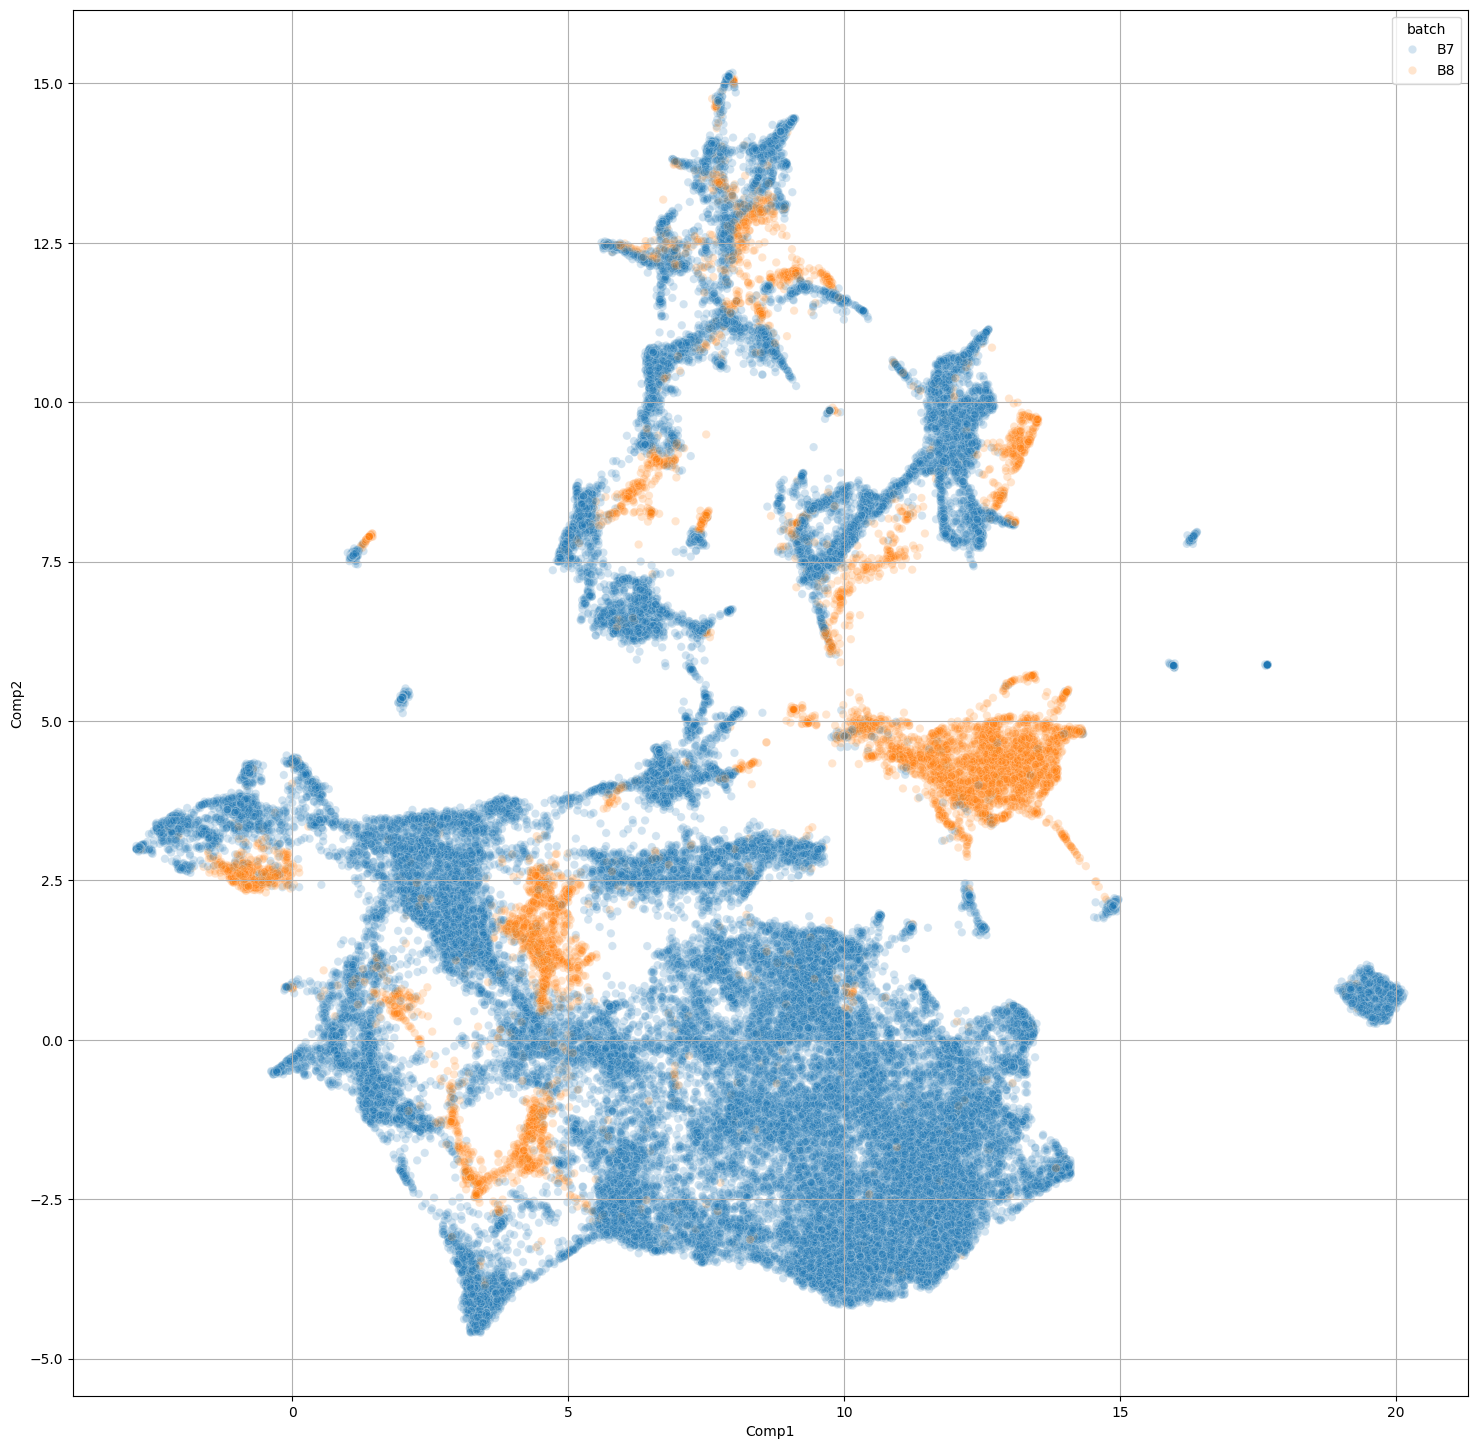

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
sns.scatterplot(umap_df.sample(fraction=.99, shuffle=True), x="Comp1", y="Comp2", hue="batch", alpha=.2, ax=ax)
ax.grid(True)

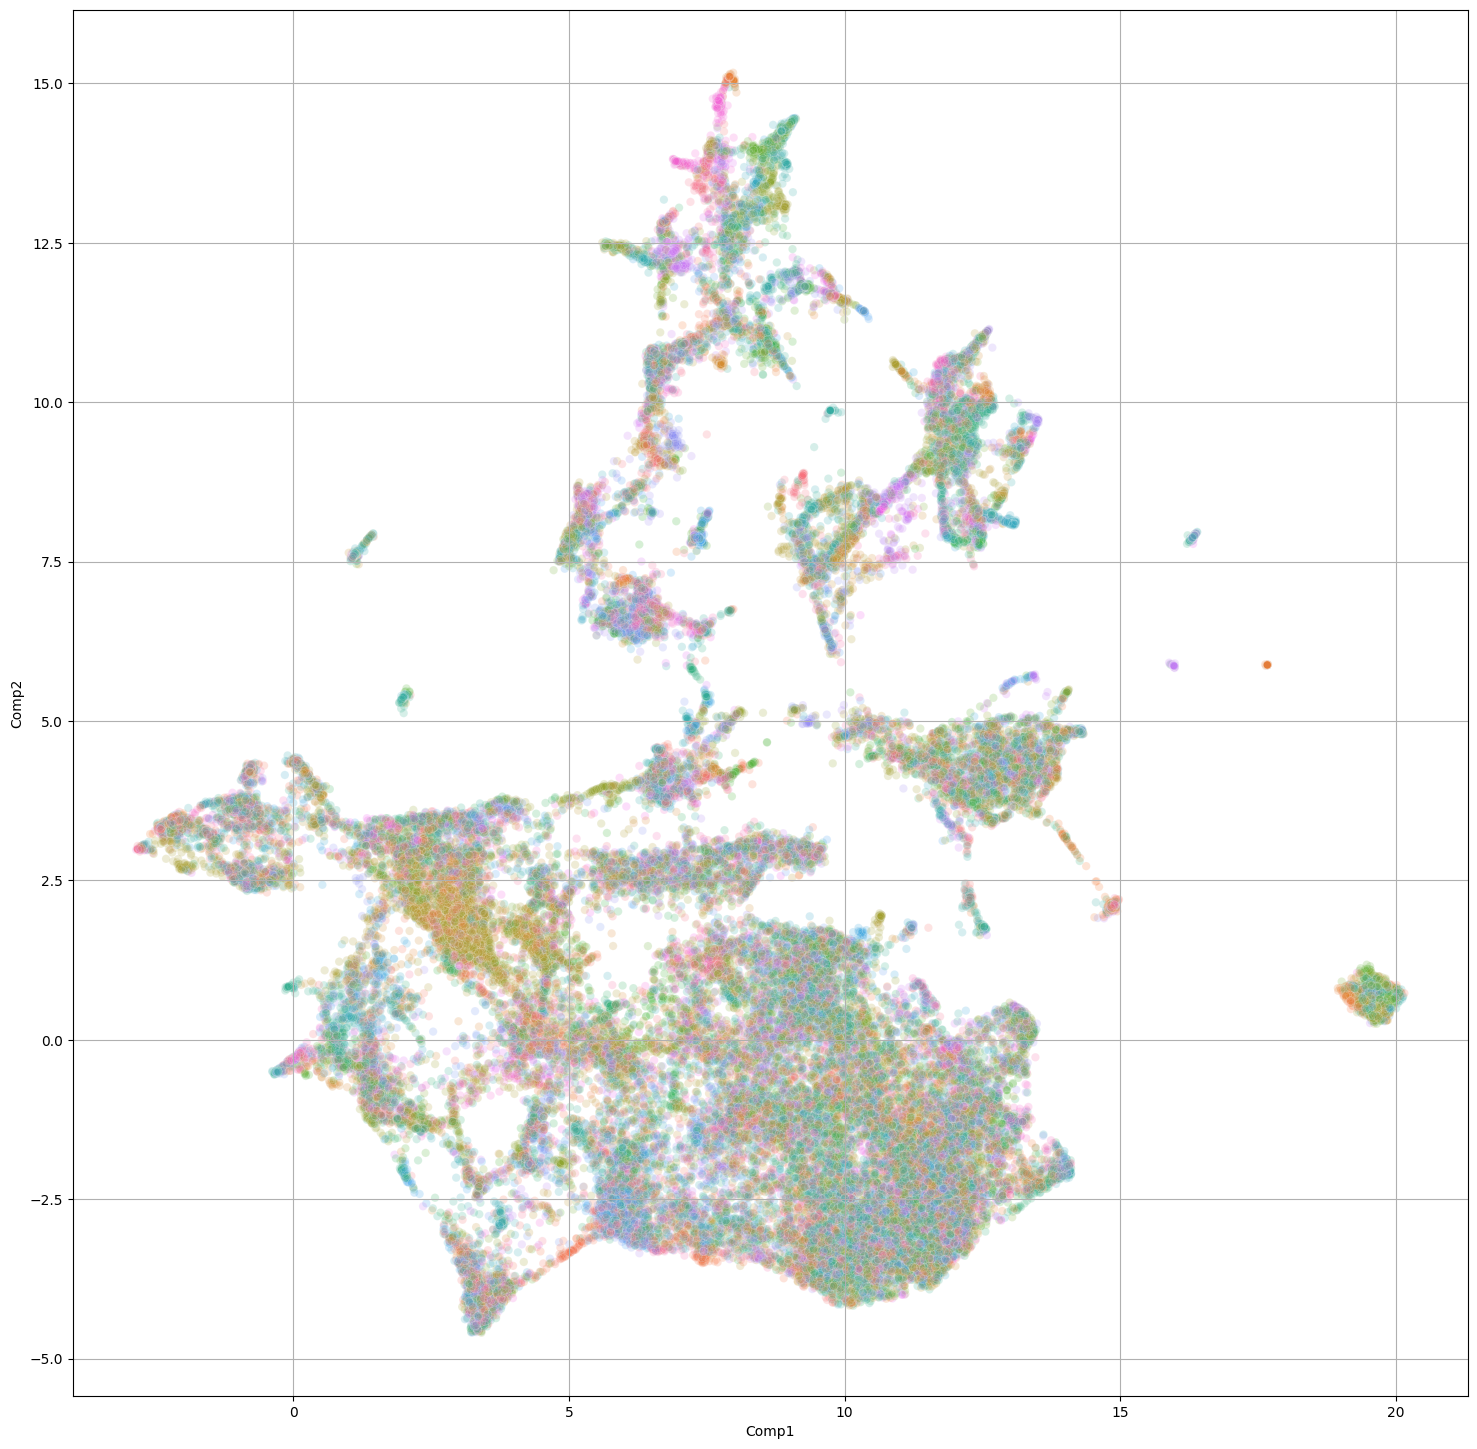

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
sns.scatterplot(umap_df, x="Comp1", y="Comp2", hue="well_position", alpha=.2, ax=ax, color="viridis", legend=False)
ax.grid(True)

2025-04-09 20:49:22,540 - WARNING - Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


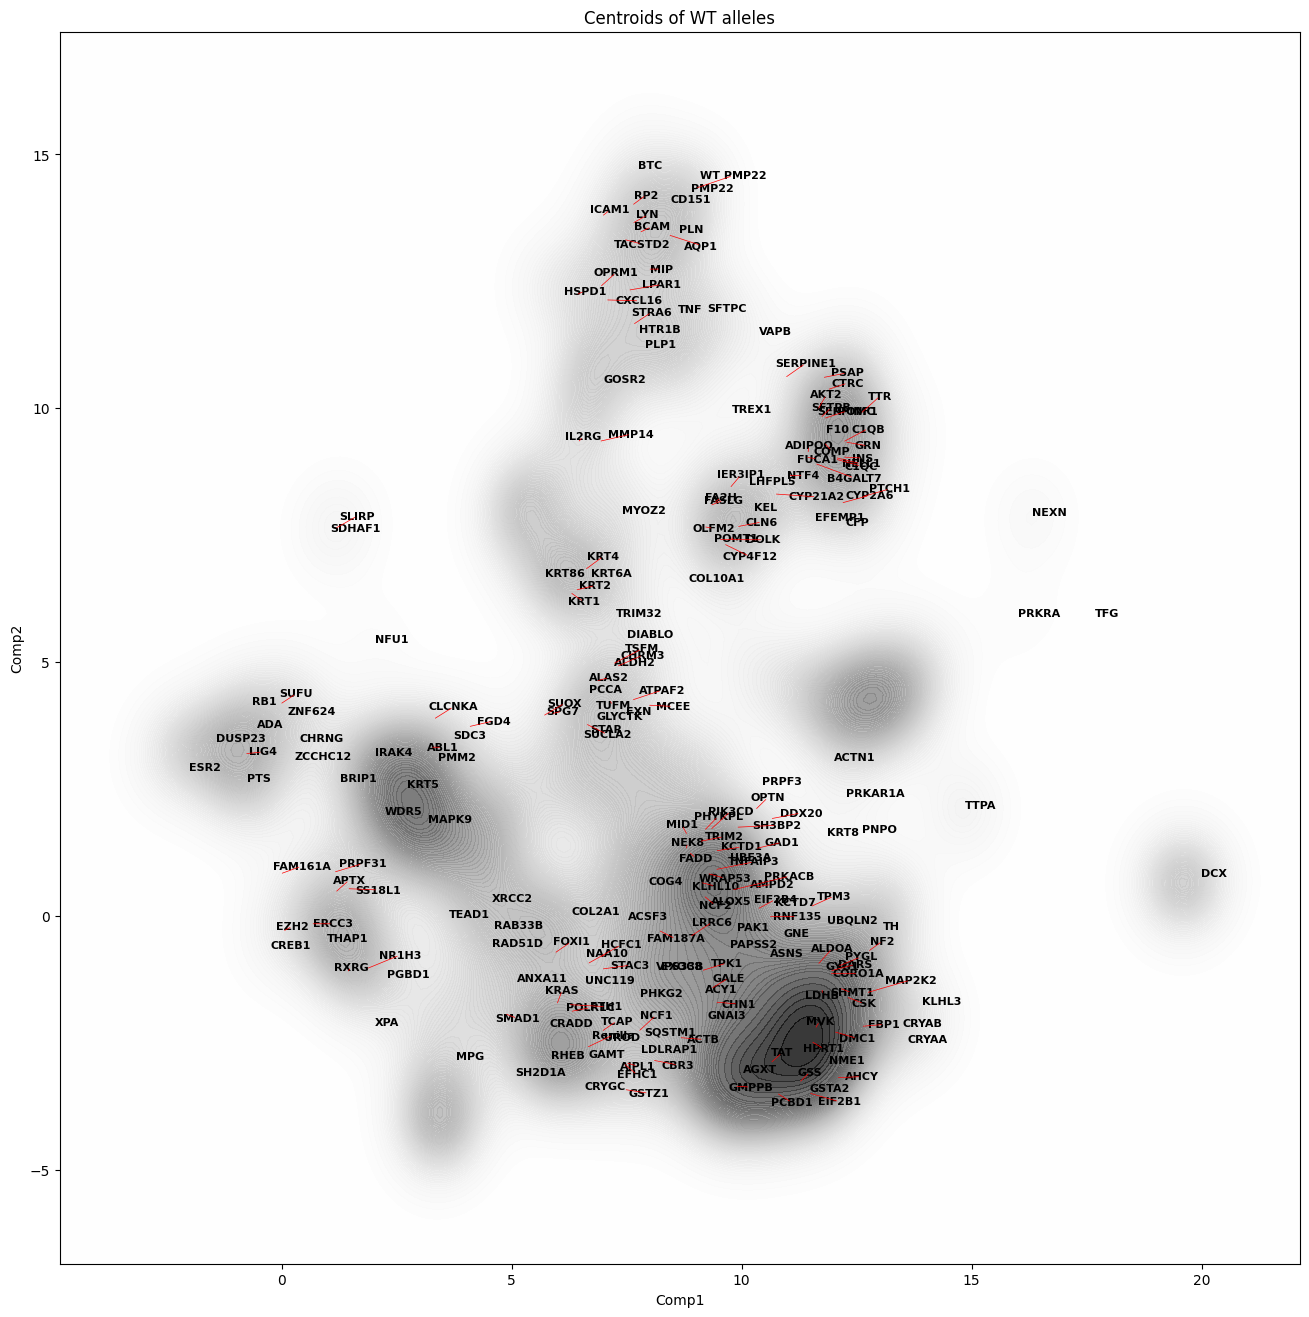

In [21]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from adjustText import adjust_text

plt.figure(figsize=(16, 16))
sns.kdeplot(data=umap_df.to_pandas(), x="Comp1", y="Comp2", fill=True, cmap="Greys", alpha=0.8, thresh=0, levels=100)

# Overlay the text labels
texts = []
for i, row in wt_centroid.to_pandas().iterrows():
    texts.append(plt.text(row["Comp1"], row["Comp2"], row["Metadata_Protein"], 
                          fontsize=8, fontweight='bold', color='black'))

# Adjust text to avoid overlaps
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5))
plt.title("Centroids of WT alleles")
plt.savefig("../trained_models/varchamp_v2/analysis/umap_figures/umap_wt_centroid_density.svg", format='svg')

In [44]:
prot_count = umap_df.group_by("Metadata_Protein").agg(pl.count().alias("Frequency"))
# prot_count

Cool, illustrative examples:
- RP2: clear mislocalization of one variant. It obviously separates from the rest.
- MYOZ2: 3 variants, >80% all piled on top of each other on one very small dot.
- LDHB: 1 variant clearly different

In [18]:
def plot_gene_umap(umap_df, gene):
    fig, ax = plt.subplots(1, 1, figsize=(18, 18))
    ax.grid(True)

    umap_df = umap_df.with_columns(
        pl.when(pl.col("Metadata_Protein").str.contains(gene))
        .then(pl.col("Metadata_Protein"))
        .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
    ).sort(f"{gene}_Variant")
    
    sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") == "000"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
    sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") != "000"), x="Comp1", y="Comp2", hue=f"{gene}_Variant", style="batch", palette="Set1", ax=ax, s=70, alpha=0.7)

<Axes: xlabel='Comp1', ylabel='Comp2'>

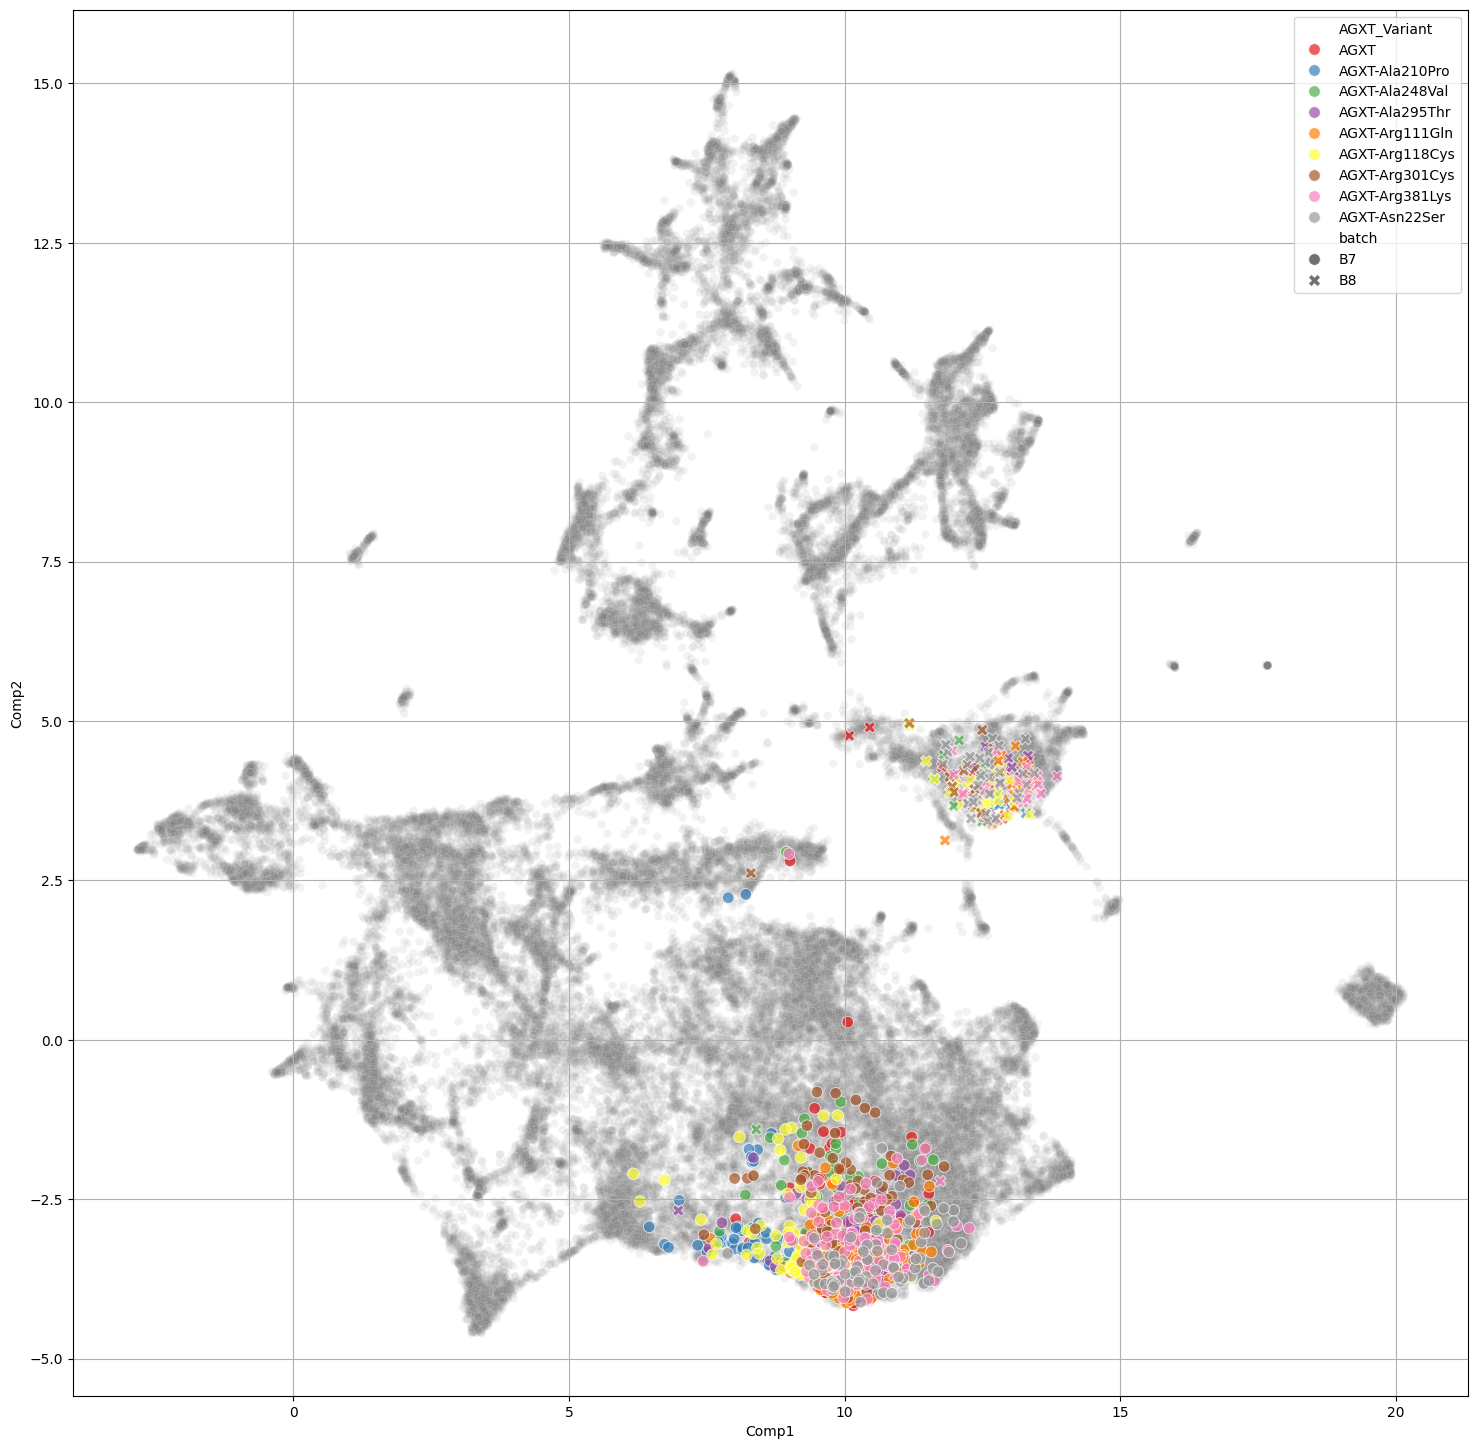

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
ax.grid(True)

list_unique_agxt = umap_df.filter(
    (pl.col("Comp1")>10)&(pl.col("Comp1")<15)&(pl.col("Comp2")>2.5)&(pl.col("Comp2")<6)&(pl.col("Metadata_Protein").str.contains("AGXT"))
).sort(pl.col("Metadata_Protein")
).select(
    pl.col("Metadata_Protein")
).unique().sort(by="Metadata_Protein").to_series().to_numpy()

gene = "AGXT"
umap_df = umap_df.with_columns(
    pl.when(pl.col("Metadata_Protein").is_in(list(list_unique_agxt)[:9]))
    .then(pl.col("Metadata_Protein"))
    .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
).sort(f"{gene}_Variant")

sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") == "000"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") != "000"), x="Comp1", y="Comp2", hue=f"{gene}_Variant", style="batch", palette="Set1", ax=ax, s=70, alpha=0.7)

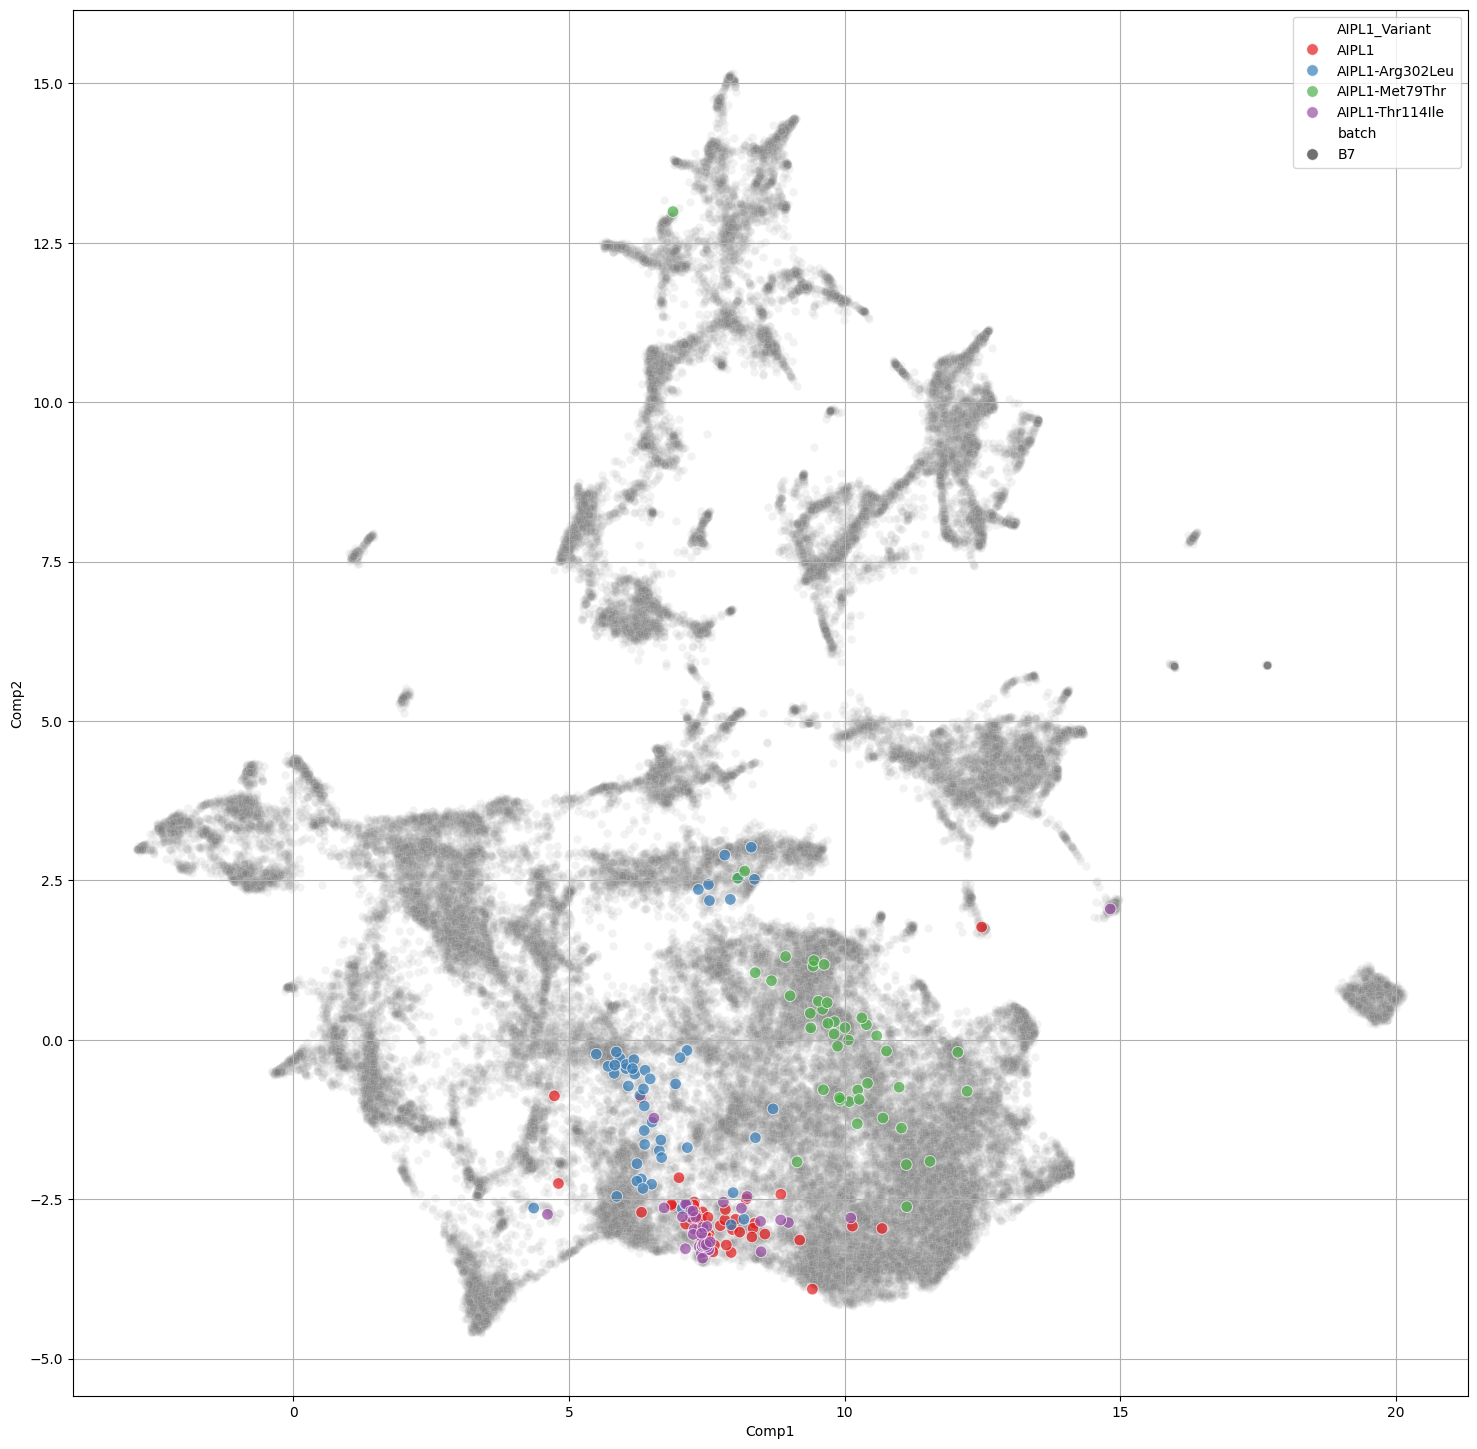

In [30]:
plot_gene_umap(umap_df, "AIPL1")

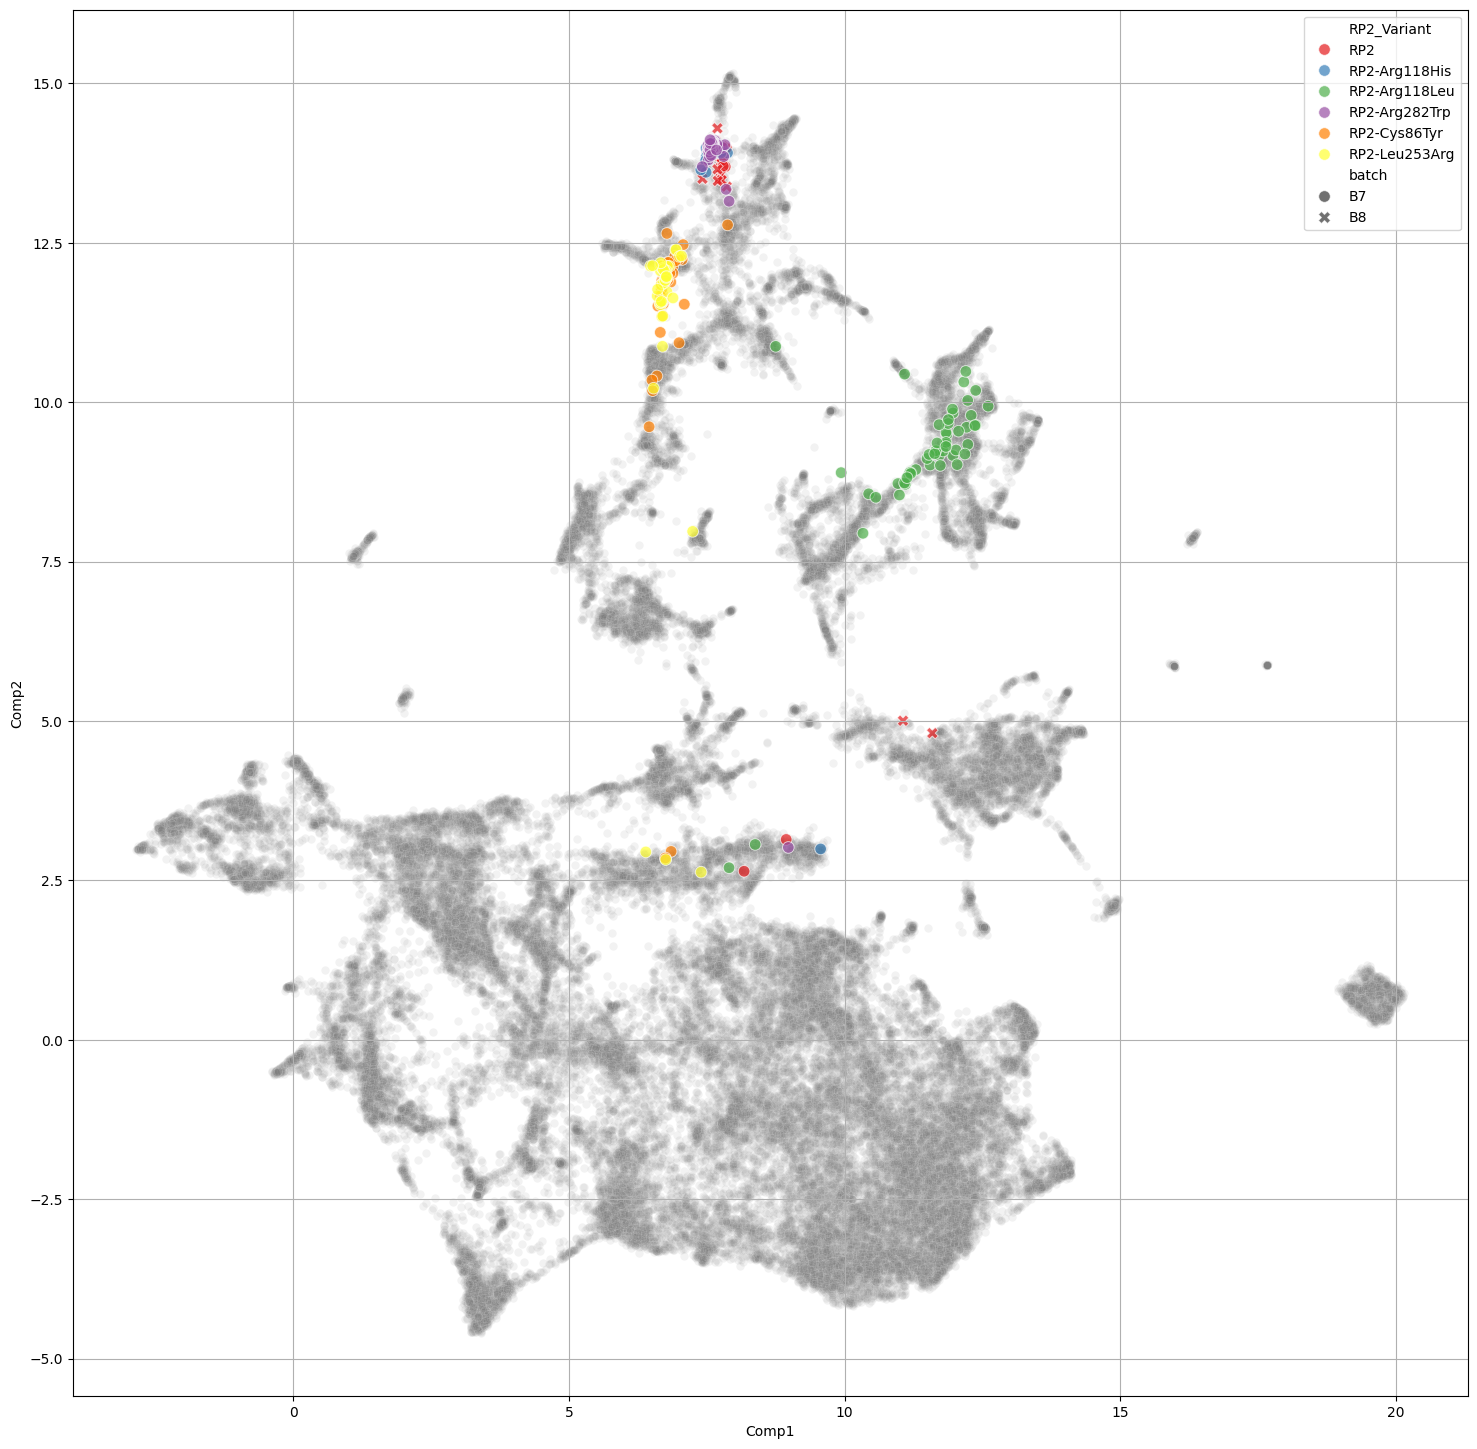

In [32]:
plot_gene_umap(umap_df, "RP2")

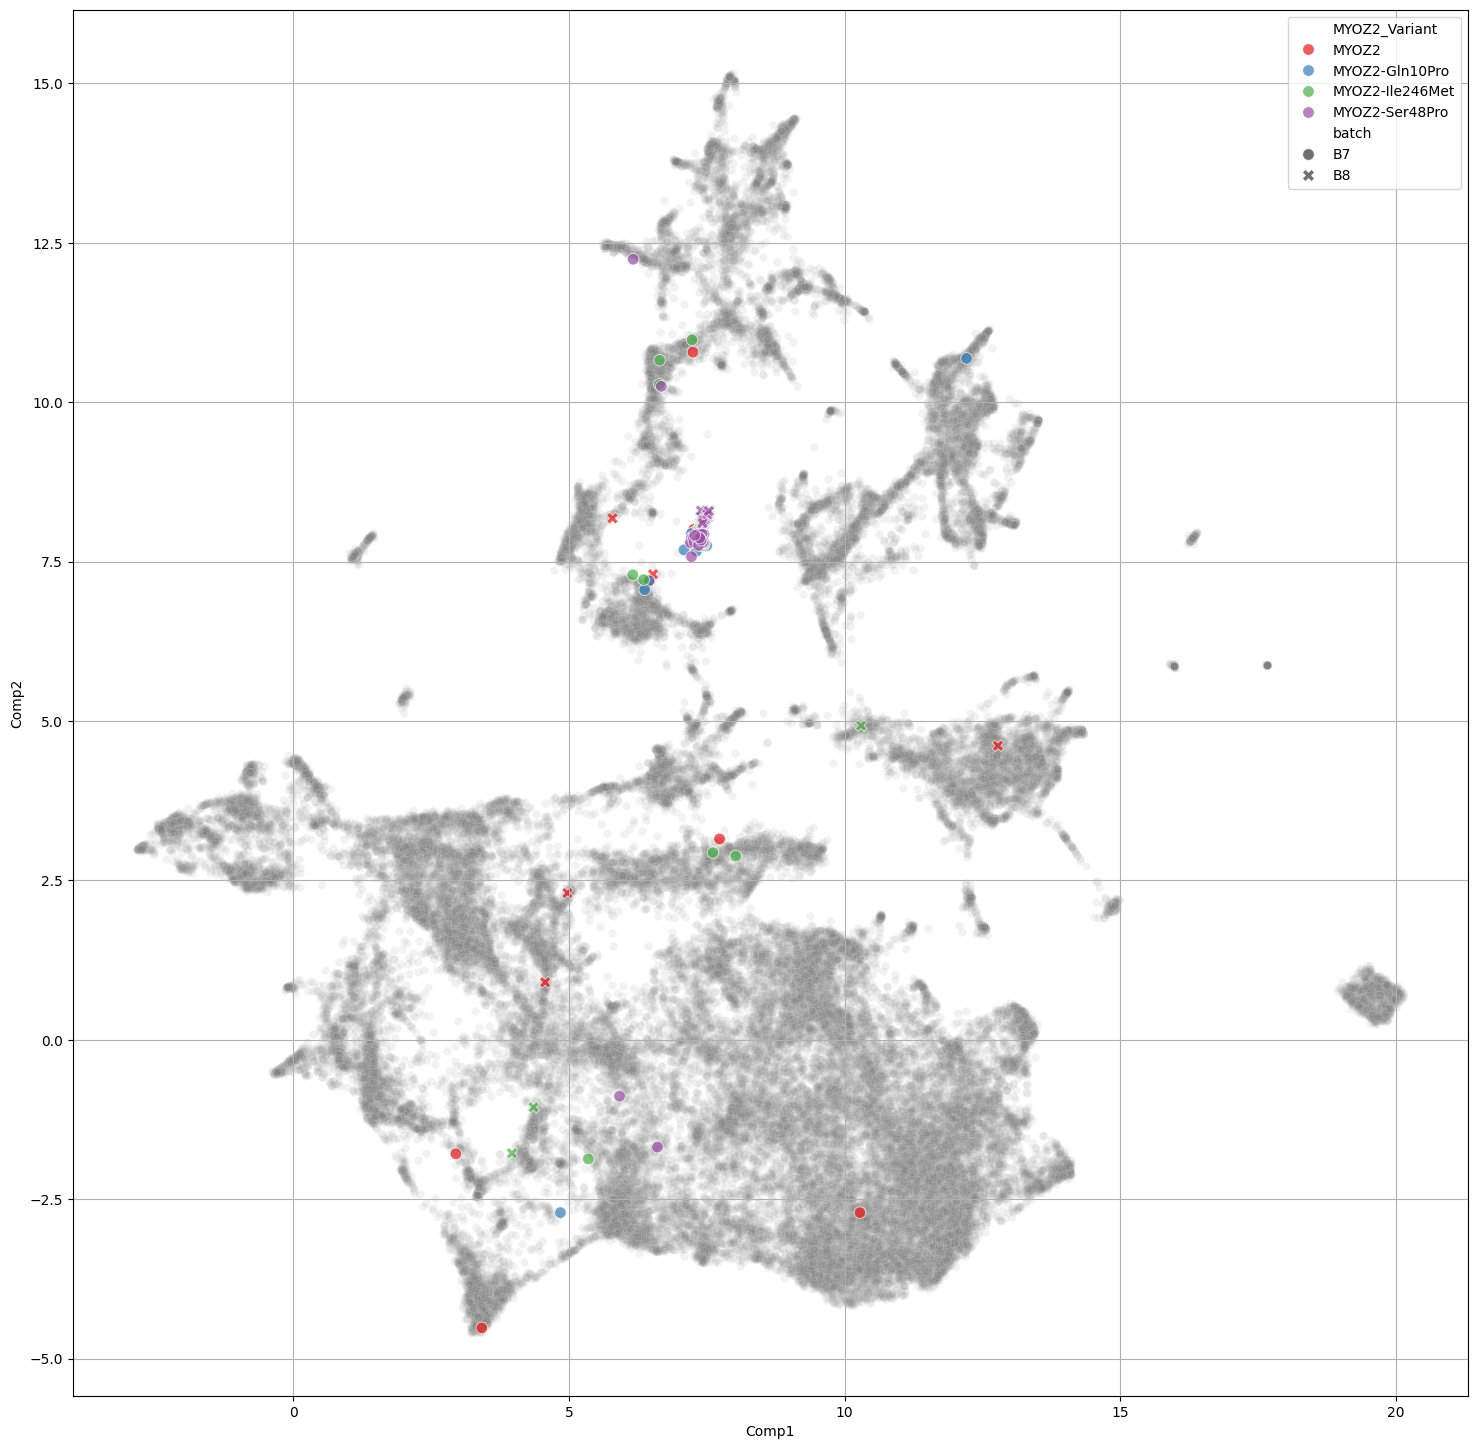

In [ ]:
plot_gene_umap(umap_df, "MYOZ2")

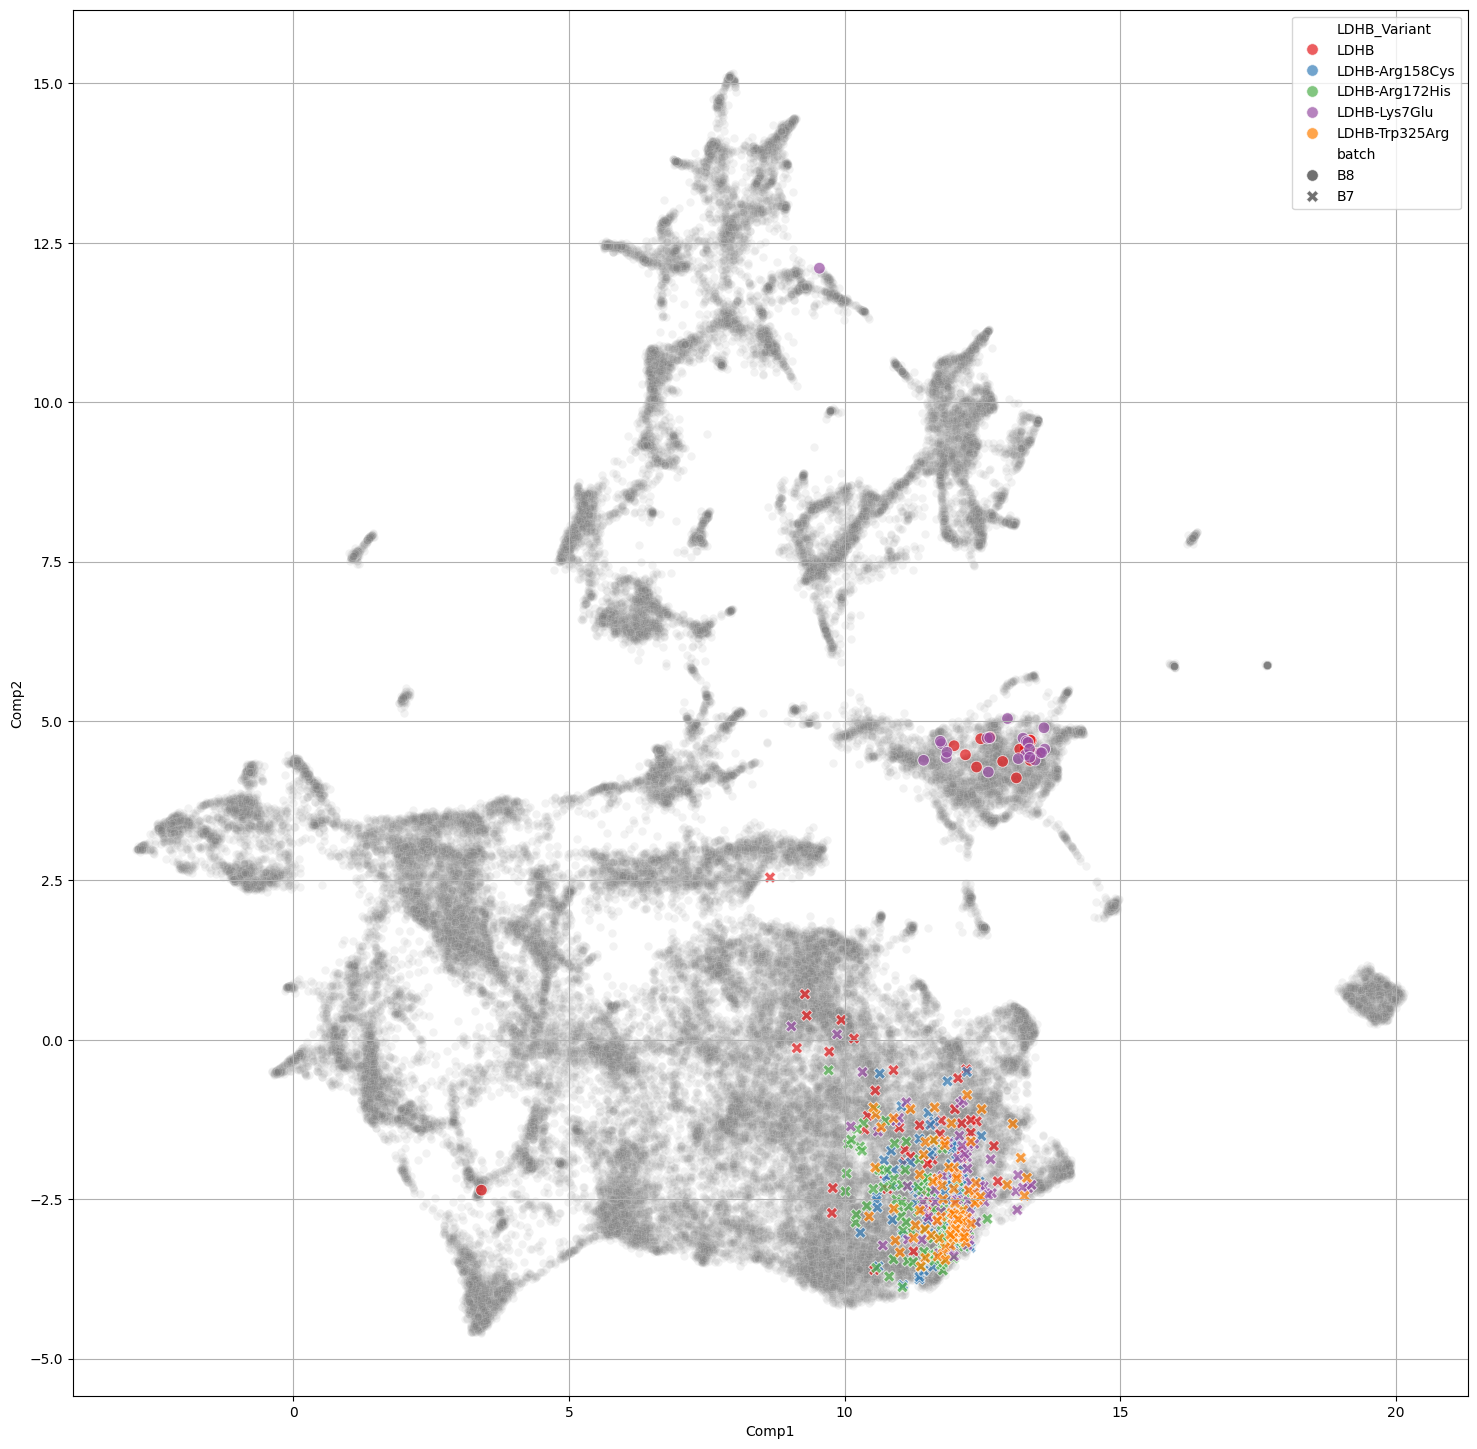

In [43]:
plot_gene_umap(umap_df, "LDHB")

## HPA subcellular annotations

In [66]:
hpa_subcell_loc = pl.read_csv("../hpa_subcellular_location_annotations/subcellular_location_data.tsv", separator="\t")
hpa_subcell_loc

umap_df_hpa = umap_df.join(hpa_subcell_loc, left_on="Gene", right_on="Gene name")
umap_df_hpa

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position,Gene,Allele_type,Gene_right,Reliability,Main location,Additional location,Extracellular location,Enhanced,Supported,Approved,Uncertain,Single-cell variation intensity,Single-cell variation spatial,Cell cycle dependency,GO id
str,str,f32,f32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""MLH1-Ser44Phe""","""2024_01_19_B7A…",8.68125,1.072259,"""B7""","""O11""","""MLH1""","""Allele""","""ENSG0000007624…","""Enhanced""","""Nucleoplasm""",null,null,"""Nucleoplasm""",null,null,null,null,null,null,"""Nucleoplasm (G…"
"""TH-Glu250Gln""","""2024_01_23_B7A…",0.064632,4.366808,"""B7""","""E16""","""TH""","""Allele""","""ENSG0000018017…","""Approved""","""Cytosol""",null,null,null,null,"""Cytosol""",null,null,null,null,"""Cytosol (GO:00…"
"""SDC3-Asp231Asn…","""2024_01_18_B7A…",3.432997,3.344314,"""B7""","""B20""","""SDC3""","""Allele""","""ENSG0000016251…","""Approved""","""Mitochondria""","""Nucleoplasm""",null,null,null,"""Mitochondria;N…",null,"""Mitochondria""",null,null,"""Mitochondria (…"
"""EIF2B4-Ala228V…","""2024_01_17_B7A…",-1.342178,3.725874,"""B7""","""L18""","""EIF2B4""","""Allele""","""ENSG0000011521…","""Approved""","""Endoplasmic re…",null,null,null,null,"""Endoplasmic re…",null,null,null,null,"""Endoplasmic re…"
"""CLN6""","""2024_01_17_B7A…",7.469278,2.878423,"""B7""","""E24""","""CLN6""","""Reference""","""ENSG0000012897…","""Approved""","""Endoplasmic re…","""Nucleoli;Vesic…",null,null,"""Endoplasmic re…",null,"""Nucleoli;Vesic…",null,null,null,"""Endoplasmic re…"
"""MLH1-Cys39Phe""","""2024_01_19_B7A…",7.821787,1.064873,"""B7""","""I05""","""MLH1""","""Allele""","""ENSG0000007624…","""Enhanced""","""Nucleoplasm""",null,null,"""Nucleoplasm""",null,null,null,null,null,null,"""Nucleoplasm (G…"
"""LDHB-Arg158Cys…","""2024_01_17_B7A…",10.284756,-3.024586,"""B7""","""D14""","""LDHB""","""Allele""","""ENSG0000011171…","""Supported""","""Cytosol""",null,null,null,"""Cytosol""",null,null,"""Cytosol""",null,null,"""Cytosol (GO:00…"
"""MLH1-Ala586Asp…","""2024_01_19_B7A…",4.219149,0.915736,"""B7""","""C13""","""MLH1""","""Allele""","""ENSG0000007624…","""Enhanced""","""Nucleoplasm""",null,null,"""Nucleoplasm""",null,null,null,null,null,null,"""Nucleoplasm (G…"
"""SMAD3-Arg287Tr…","""2024_02_05_B8A…",3.237351,-2.099868,"""B8""","""I07""","""SMAD3""","""Allele""","""ENSG0000016694…","""Enhanced""","""Nucleoplasm""","""Basal body;Pri…",null,"""Nucleoplasm;Ve…","""Primary cilium…","""Basal body""",null,"""Basal body;Pri…",null,null,"""Basal body (GO…"


In [67]:
umap_df_hpa["Main location"].unique()

Main location
str
"""Mitochondria"""
"""Cytosol;Interm…"
"""Endoplasmic re…"
"""Mid piece"""
"""Nuclear membra…"
"""Cytosol;Vesicl…"
"""Cytosol;Golgi …"
"""Lysosomes"""
"""Basal body;Pla…"


In [72]:
umap_df_hpa = umap_df_hpa.with_columns(
    pl.when(pl.col("Main location").str.contains(";"))
    .then(pl.lit("Multiple"))
    .otherwise(pl.col("Main location"))
    .alias("Subcell_Loc")
)
umap_df_hpa["Subcell_Loc"].unique()

Subcell_Loc
str
"""Multiple"""
"""Centrosome"""
"""Endoplasmic re…"
"""Lysosomes"""
"""Actin filament…"
"""Acrosome"""
"""Mid piece"""
"""Nuclear speckl…"
"""Nucleoli"""


In [90]:
# get_custom_colormap(20)

/tmp/ipykernel_211678/2644162304.py:11: UserWarning: The palette list has more values (21) than needed (16), which may not be intended.
  sns.scatterplot(umap_df_hpa.filter((pl.col("Allele_type")!="Gene")&(pl.col("Subcell_Loc")!="Multiple")&(pl.col("Additional location").is_not_null())), x="Comp1", y="Comp2",


<Axes: xlabel='Comp1', ylabel='Comp2'>

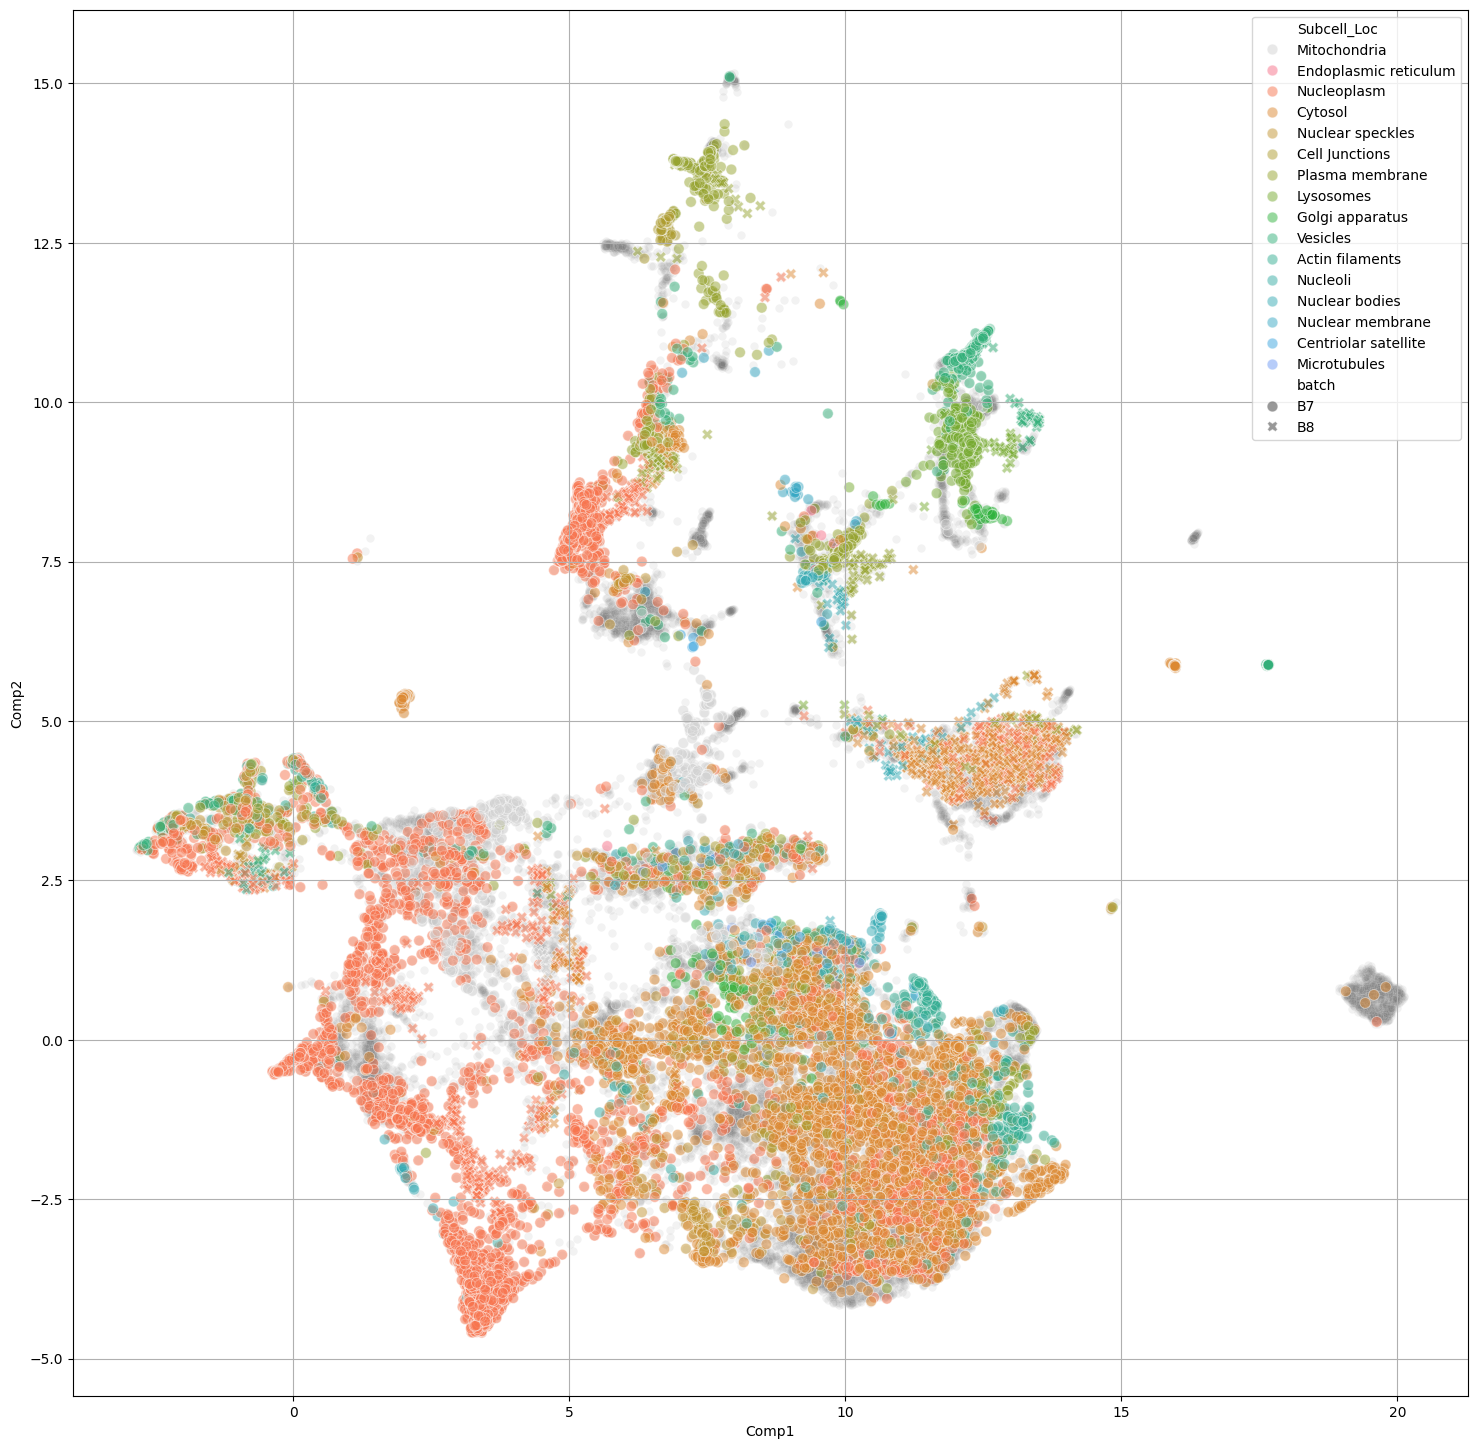

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
ax.grid(True)

# umap_df = umap_df.with_columns(
#     pl.when(pl.col("Allele_type").is_in(list(list_unique_agxt)[:9]))
#     .then(pl.col("Metadata_Protein"))
#     .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
# ).sort(f"{gene}_Variant")

sns.scatterplot(umap_df_hpa.filter(pl.col("Allele_type") == "Allele"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
sns.scatterplot(umap_df_hpa.filter(
    (pl.col("Allele_type")!="Gene")&(pl.col("Subcell_Loc")!="Multiple")&(pl.col("Additional location").is_not_null())
), x="Comp1", y="Comp2", 
hue=f"Subcell_Loc", style="batch", palette=get_custom_colormap(20), ax=ax, s=60, alpha=0.5)

Next steps:
- Reproduce their cluster analysis with GO:CC and Corum complexes. Try implement the idea that I had for spatial enrichment. 
- Adapt pooled-rare plotting functions for the Varchamp data so that I can look up specific cells based on the UMAP location.
- Make comparable UMAPs with CellProfiler features: use all same QA/QC filters, plus downsample to ~10%